In [2]:
# data processing
import pandas as pd
import numpy as np

# viz tools
import matplotlib.pyplot as plt
import seaborn as sns

# evaluation metrics
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix

#regression
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split

#psm
from causalinference import CausalModel
import statsmodels.formula.api as smf

#warnings
import warnings
warnings.filterwarnings('ignore')
# set to display all columns
pd.set_option('display.max_columns', None)

In [3]:
file_path = "Telco_customer_churn_adapted_v2.xlsx"
df = pd.read_excel(file_path)

df["Internet"] = np.where(df["Games Product"] == "No internet service", 0 , 1)
products = ['Games Product', 'Music Product', 'Education Product', 'Call Center','Video Product', 'Use MyApp']
df[products] = df[products].replace({'No internet service': 'No'})

encoded_df = pd.concat([df, 
                        pd.get_dummies(df[['Device Class', 'Payment Method', 'Games Product', 'Music Product', 'Education Product', 'Call Center', 'Video Product', 'Use MyApp', 'Churn Label']], 
                            prefix=['Device_Class', 'Payment Method', 'Games Product', 'Music Product', 'Education Product', 'Call Center', 'Video Product', 'Use MyApp', 'Churn Label'],
                            drop_first=True)], axis=1)

fin_df = encoded_df.drop(['Longitude', 'Latitude', 'Location',
             'Location', 'Churn Label', 'Device Class', 'Games Product', 'Payment Method',
             'Games Product', 'Music Product', 'Education Product', 'Call Center', 'Video Product', 'Use MyApp'], axis=1)

user_df = fin_df[fin_df['Internet'] == 1].drop('Internet', axis = 1)

user_df

,Customer ID,Tenure Months,Monthly Purchase (Thou. IDR),CLTV (Predicted Thou. IDR),Device_Class_Low End,Device_Class_Mid End,Payment Method_Debit,Payment Method_Digital Wallet,Payment Method_Pulsa,Games Product_Yes,Music Product_Yes,Education Product_Yes,Call Center_Yes,Video Product_Yes,Use MyApp_Yes,Churn Label_Yes
0,0,2,70.005,4210.7,False,True,False,True,False,True,True,False,False,False,False,True
1,1,2,91.910,3511.3,False,False,False,False,True,False,False,False,False,False,False,True
2,2,8,129.545,6983.6,False,False,False,False,True,False,False,True,False,True,True,True
3,3,28,136.240,6503.9,False,False,False,False,True,False,False,True,True,True,True,True
4,4,49,134.810,6942.0,False,False,True,False,False,False,True,True,False,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,7037,12,78.845,4862.0,False,True,False,False,True,False,True,True,True,True,True,False
7039,7039,24,110.240,2782.0,False,True,False,True,False,True,False,True,True,True,True,False
7040,7040,72,134.160,7228.0,False,False,False,False,False,False,True,True,False,True,True,False
7041,7041,11,38.480,3630.9,False,True,False,False,True,True,False,False,False,False,False,False


In [4]:
fin_df.groupby('Internet')['Churn Label_Yes'].mean()

Internet
0    0.074050
1    0.318289
Name: Churn Label_Yes, dtype: float64

In [5]:
fin_df.groupby('Internet')['Monthly Purchase (Thou. IDR)'].mean()

Internet
0    27.402952
1    99.897530
Name: Monthly Purchase (Thou. IDR), dtype: float64

In [6]:
fin_df.groupby('Internet')['CLTV (Predicted Thou. IDR)'].mean()

Internet
0    5686.696658
1    5729.702519
Name: CLTV (Predicted Thou. IDR), dtype: float64

In [7]:
from sklearn.linear_model import LogisticRegression

T = 'Call Center_Yes'
Y = 'Churn Label_Yes'
notY = ['Monthly Purchase (Thou. IDR)', 'CLTV (Predicted Thou. IDR)']
notX = []
X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

data_ps

,Customer ID,Tenure Months,Monthly Purchase (Thou. IDR),CLTV (Predicted Thou. IDR),Device_Class_Low End,Device_Class_Mid End,Payment Method_Debit,Payment Method_Digital Wallet,Payment Method_Pulsa,Games Product_Yes,Music Product_Yes,Education Product_Yes,Call Center_Yes,Video Product_Yes,Use MyApp_Yes,Churn Label_Yes,propensity_score
0,0,2,70.005,4210.7,False,True,False,True,False,True,True,False,False,False,False,True,0.363575
1,1,2,91.910,3511.3,False,False,False,False,True,False,False,False,False,False,False,True,0.053114
2,2,8,129.545,6983.6,False,False,False,False,True,False,False,True,False,True,True,True,0.153878
3,3,28,136.240,6503.9,False,False,False,False,True,False,False,True,True,True,True,True,0.223388
4,4,49,134.810,6942.0,False,False,True,False,False,False,True,True,False,True,True,True,0.475634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,7037,12,78.845,4862.0,False,True,False,False,True,False,True,True,True,True,True,False,0.378010
7039,7039,24,110.240,2782.0,False,True,False,True,False,True,False,True,True,True,True,False,0.693225
7040,7040,72,134.160,7228.0,False,False,False,False,False,False,True,True,False,True,True,False,0.615621
7041,7041,11,38.480,3630.9,False,True,False,False,True,True,False,False,False,False,False,False,0.220071


In [8]:
cm = CausalModel(
    Y=data_ps['Churn Label_Yes'].values, 
    D=data_ps["Call Center_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=5, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE     -0.092      0.016     -5.696      0.000     -0.124     -0.060
           ATC     -0.109      0.019     -5.758      0.000     -0.146     -0.072
           ATT     -0.063      0.020     -3.232      0.001     -0.101     -0.025



In [9]:
from sklearn.linear_model import LogisticRegression

T = 'Call Center_Yes'
Y = 'Monthly Purchase (Thou. IDR)'
notY = ['Churn Label_Yes', 'CLTV (Predicted Thou. IDR)']
notX = []
X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

data_ps

,Customer ID,Tenure Months,Monthly Purchase (Thou. IDR),CLTV (Predicted Thou. IDR),Device_Class_Low End,Device_Class_Mid End,Payment Method_Debit,Payment Method_Digital Wallet,Payment Method_Pulsa,Games Product_Yes,Music Product_Yes,Education Product_Yes,Call Center_Yes,Video Product_Yes,Use MyApp_Yes,Churn Label_Yes,propensity_score
0,0,2,70.005,4210.7,False,True,False,True,False,True,True,False,False,False,False,True,0.363575
1,1,2,91.910,3511.3,False,False,False,False,True,False,False,False,False,False,False,True,0.053114
2,2,8,129.545,6983.6,False,False,False,False,True,False,False,True,False,True,True,True,0.153878
3,3,28,136.240,6503.9,False,False,False,False,True,False,False,True,True,True,True,True,0.223388
4,4,49,134.810,6942.0,False,False,True,False,False,False,True,True,False,True,True,True,0.475634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,7037,12,78.845,4862.0,False,True,False,False,True,False,True,True,True,True,True,False,0.378010
7039,7039,24,110.240,2782.0,False,True,False,True,False,True,False,True,True,True,True,False,0.693225
7040,7040,72,134.160,7228.0,False,False,False,False,False,False,True,True,False,True,True,False,0.615621
7041,7041,11,38.480,3630.9,False,True,False,False,True,True,False,False,False,False,False,False,0.220071


In [10]:
cm = CausalModel(
    Y=data_ps["Monthly Purchase (Thou. IDR)"].values, 
    D=data_ps["Call Center_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=5, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE      6.310      1.132      5.572      0.000      4.090      8.529
           ATC      6.199      1.390      4.458      0.000      3.474      8.924
           ATT      6.498      1.220      5.325      0.000      4.106      8.890



In [11]:
from sklearn.linear_model import LogisticRegression

T = 'Call Center_Yes'
Y = 'CLTV (Predicted Thou. IDR)'
notY = ['Churn Label_Yes', 'Monthly Purchase (Thou. IDR)'] 
notX = []
X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

data_ps

,Customer ID,Tenure Months,Monthly Purchase (Thou. IDR),CLTV (Predicted Thou. IDR),Device_Class_Low End,Device_Class_Mid End,Payment Method_Debit,Payment Method_Digital Wallet,Payment Method_Pulsa,Games Product_Yes,Music Product_Yes,Education Product_Yes,Call Center_Yes,Video Product_Yes,Use MyApp_Yes,Churn Label_Yes,propensity_score
0,0,2,70.005,4210.7,False,True,False,True,False,True,True,False,False,False,False,True,0.363575
1,1,2,91.910,3511.3,False,False,False,False,True,False,False,False,False,False,False,True,0.053114
2,2,8,129.545,6983.6,False,False,False,False,True,False,False,True,False,True,True,True,0.153878
3,3,28,136.240,6503.9,False,False,False,False,True,False,False,True,True,True,True,True,0.223388
4,4,49,134.810,6942.0,False,False,True,False,False,False,True,True,False,True,True,True,0.475634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,7037,12,78.845,4862.0,False,True,False,False,True,False,True,True,True,True,True,False,0.378010
7039,7039,24,110.240,2782.0,False,True,False,True,False,True,False,True,True,True,True,False,0.693225
7040,7040,72,134.160,7228.0,False,False,False,False,False,False,True,True,False,True,True,False,0.615621
7041,7041,11,38.480,3630.9,False,True,False,False,True,True,False,False,False,False,False,False,0.220071


In [12]:
cm = CausalModel(
    Y=data_ps['CLTV (Predicted Thou. IDR)'].values, 
    D=data_ps["Call Center_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=5, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE     29.591     59.591      0.497      0.619    -87.207    146.389
           ATC     39.714     72.155      0.550      0.582   -101.710    181.138
           ATT     12.390     66.723      0.186      0.853   -118.387    143.168



## Video

In [13]:
from sklearn.linear_model import LogisticRegression

T = 'Video Product_Yes'
Y = 'Churn Label_Yes'
notY = ['CLTV (Predicted Thou. IDR)', 'Monthly Purchase (Thou. IDR)'] 
notX = ['Call Center_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [14]:
cm = CausalModel(
    Y=data_ps["Churn Label_Yes"].values, 
    D=data_ps["Video Product_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=8, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE      0.052      0.016      3.192      0.001      0.020      0.084
           ATC      0.061      0.019      3.182      0.001      0.023      0.098
           ATT      0.044      0.020      2.222      0.026      0.005      0.082



In [15]:
from sklearn.linear_model import LogisticRegression

T = 'Video Product_Yes'
Y = 'Monthly Purchase (Thou. IDR)'
notY = ['CLTV (Predicted Thou. IDR)', 'Churn Label_Yes'] 
notX = ['Call Center_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [16]:
cm = CausalModel(
    Y=data_ps['Monthly Purchase (Thou. IDR)'].values, 
    D=data_ps["Video Product_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=8, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE     13.496      0.664     20.322      0.000     12.194     14.797
           ATC     13.930      0.778     17.896      0.000     12.404     15.455
           ATT     13.045      0.790     16.523      0.000     11.498     14.592



In [52]:
from sklearn.linear_model import LogisticRegression

T = 'Video Product_Yes'
Y = 'CLTV (Predicted Thou. IDR)'
notY = ['Monthly Purchase (Thou. IDR)', 'Churn Label_Yes'] 
notX = ['Call Center_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [53]:
cm = CausalModel(
    Y=data_ps['CLTV (Predicted Thou. IDR)'].values, 
    D=data_ps["Video Product_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=7, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE    -48.068     54.528     -0.882      0.378   -154.943     58.807
           ATC    -73.215     62.900     -1.164      0.244   -196.499     50.069
           ATT    -21.963     66.262     -0.331      0.740   -151.837    107.910



In [54]:
from joblib import Parallel, delayed # for parallel processing

# define function that computes the IPTW estimator
def run_ps(df, X, T, y):
    # estimate the propensity score
    ps = LogisticRegression(C=1e6, max_iter=1000).fit(df[X], df[T]).predict_proba(df[X])[:, 1]
    
    weight = (df[T]-ps) / (ps*(1-ps)) # define the weights
    return np.mean(weight * df[y]) # compute the ATE

np.random.seed(88)
# run 1000 bootstrap samples
bootstrap_sample = 1000
ates = Parallel(n_jobs=4)(delayed(run_ps)(user_df.sample(frac=1, replace=True), X, T, Y)
                          for _ in range(bootstrap_sample))
ates = np.array(ates)


In [55]:
print(f"ATE: {ates.mean()}")
print(f"95% C.I.: {(np.percentile(ates, 2.5), np.percentile(ates, 97.5))}")


ATE: 18.999352242461214
95% C.I.: (-105.27111976998874, 146.6804542353386)


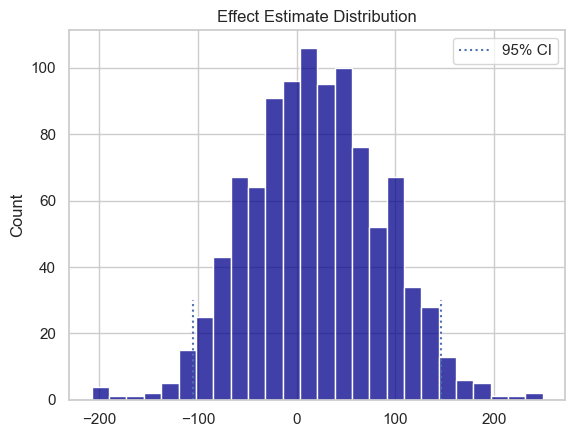

In [56]:
sns.set(style="whitegrid")
ax = sns.histplot(ates, kde=False, color = "darkblue")
plt.vlines(np.percentile(ates, 2.5), 0, 30, linestyles="dotted")
plt.vlines(np.percentile(ates, 97.5), 0, 30, linestyles="dotted", label="95% CI")
plt.title("Effect Estimate Distribution")
plt.legend()
plt.savefig("images/video_cltv.jpg")


## MyApp

In [23]:
from sklearn.linear_model import LogisticRegression

T = 'Use MyApp_Yes'
Y = 'Churn Label_Yes'
notY = ['CLTV (Predicted Thou. IDR)', 'Monthly Purchase (Thou. IDR)'] 
notX = ['Call Center_Yes', 'Games Product_Yes', 'Video Product_Yes', 'Education Product_Yes', 'Music Product_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [24]:
cm = CausalModel(
    Y=data_ps['Churn Label_Yes'].values, 
    D=data_ps["Use MyApp_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=8, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE      0.062      0.014      4.517      0.000      0.035      0.089
           ATC      0.083      0.015      5.363      0.000      0.053      0.113
           ATT      0.042      0.015      2.690      0.007      0.011      0.072



In [25]:
from sklearn.linear_model import LogisticRegression

T = 'Use MyApp_Yes'
Y = 'Monthly Purchase (Thou. IDR)'
notY = ['CLTV (Predicted Thou. IDR)', 'Churn Label_Yes' ] 
notX = ['Call Center_Yes', 'Games Product_Yes', 'Video Product_Yes', 'Education Product_Yes', 'Music Product_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [26]:
cm = CausalModel(
    Y=data_ps['Monthly Purchase (Thou. IDR)'].values, 
    D=data_ps["Use MyApp_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=8, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE     18.819      0.591     31.837      0.000     17.660     19.977
           ATC     19.449      0.670     29.013      0.000     18.135     20.763
           ATT     18.176      0.652     27.885      0.000     16.899     19.454



In [57]:
from sklearn.linear_model import LogisticRegression

T = 'Use MyApp_Yes'
Y = 'CLTV (Predicted Thou. IDR)'
notY = ['Monthly Purchase (Thou. IDR)', 'Churn Label_Yes' ] 
notX = ['Call Center_Yes', 'Games Product_Yes', 'Video Product_Yes', 'Education Product_Yes', 'Music Product_Yes']

X = user_df.columns.drop(notX).drop(notY).drop(['Customer ID', T, Y])

ps_model = LogisticRegression(C=1e6).fit(user_df[X], user_df[T])

data_ps = user_df.assign(propensity_score=ps_model.predict_proba(user_df[X])[:, 1])

In [58]:
cm = CausalModel(
    Y=data_ps['CLTV (Predicted Thou. IDR)'].values, 
    D=data_ps["Use MyApp_Yes"].values, 
    X=data_ps[["propensity_score"]].values
)

cm.est_via_matching(matches=8, bias_adj=True)

print(cm.estimates)


Treatment Effect Estimates: Matching

                     Est.       S.e.          z      P>|z|      [95% Conf. int.]
--------------------------------------------------------------------------------
           ATE    -43.151     44.803     -0.963      0.335   -130.965     44.662
           ATC    -82.829     49.829     -1.662      0.096   -180.494     14.836
           ATT     -2.704     50.390     -0.054      0.957   -101.469     96.061



In [59]:
from joblib import Parallel, delayed # for parallel processing

# define function that computes the IPTW estimator
def run_ps(df, X, T, y):
    # estimate the propensity score
    ps = LogisticRegression(C=1e6, max_iter=1000).fit(df[X], df[T]).predict_proba(df[X])[:, 1]
    
    weight = (df[T]-ps) / (ps*(1-ps)) # define the weights
    return np.mean(weight * df[y]) # compute the ATE

np.random.seed(88)
# run 1000 bootstrap samples
bootstrap_sample = 1000
ates = Parallel(n_jobs=4)(delayed(run_ps)(user_df.sample(frac=1, replace=True), X, T, Y)
                          for _ in range(bootstrap_sample))
ates = np.array(ates)


In [60]:
print(f"ATE: {ates.mean()}")
print(f"95% C.I.: {(np.percentile(ates, 2.5), np.percentile(ates, 97.5))}")


ATE: -27.218128239341137
95% C.I.: (-127.38443608519567, 80.01620595755293)


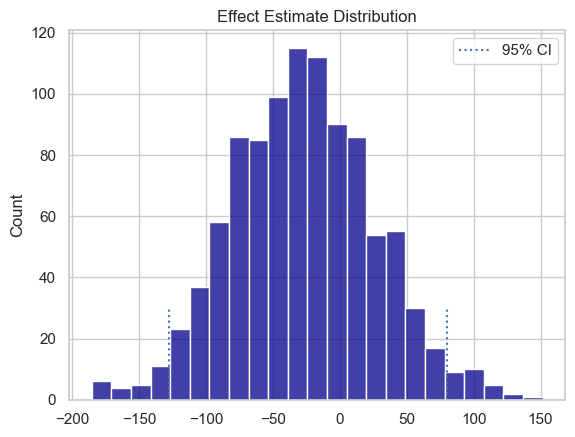

In [61]:
sns.set(style="whitegrid")
ax = sns.histplot(ates, kde=False, color = "darkblue")
plt.vlines(np.percentile(ates, 2.5), 0, 30, linestyles="dotted")
plt.vlines(np.percentile(ates, 97.5), 0, 30, linestyles="dotted", label="95% CI")
plt.title("Effect Estimate Distribution")
plt.legend()
plt.savefig("images/myapp_cltv.jpg")


In [28]:
def effectdirection(value):
    if value > 0:
        return "increase"
    else:
        return "decrease"

churn_effects = {'Call Center': -0.108, 'Video': 0.060, 'MyApp' : 0.083}
abs_churn_effect = {key: abs(val) for key, val in churn_effects.items()}
direction_churn_effect = {key: effectdirection(val) for key, val in churn_effects.items()}


In [29]:
abs_churn_effect

{'Call Center': 0.108, 'Video': 0.06, 'MyApp': 0.083}

In [30]:
direction_churn_effect

{'Call Center': 'decrease', 'Video': 'increase', 'MyApp': 'increase'}